In [1]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

from grakel.datasets import fetch_dataset
from grakel.kernels import ShortestPath, RandomWalk

from grakel import Kernel, Graph

import networkx as nx

import matplotlib.pylab as plt

plt.rcParams['figure.figsize'] = [15, 15]

In [2]:
def get_graph(edges, nodes):
    g = nx.Graph()
    #g.add_weighted_edges_from(edges)
    #g.add_nodes_from(nodes)
    g.add_edges_from(edges)

    g.add_nodes_from(nodes)
    
    return g

def get_adjacency(g, N):
    A = nx.adjacency_matrix(g).toarray()
    M = A.shape[0]
    A = np.pad(A, [(0, N-M), (0, N-M)], mode='constant')
    return A

def matrix_prod_trace(A,B):
    n = len(A)
    diag_sum = 0
    for i in range(n):
        diag_sum += np.matmul(A[i,:],B[:,i])
    return diag_sum

In [3]:
nodes = ['1', '2', '3', '4', 'a', 'b', 'c']

In [4]:
edges1 = [['1', '2'], ['1', '3'], ['2', '3']]
edges2 = [['a', 'b'], ['b', 'c']]
edges3 = [['1', '2'], ['1', 'c'], ['b', '1'], ['a', '1']]
edges4 = [['1', '2'], ['2', '3'], ['1', '3'], ['3', '4']]

In [5]:
edges = [edges1, edges2, edges3, edges4]
nodes = ['1', '2', '3', '4', 'a', 'b', 'c']

num_graph = 4
graphs = []
for i in range(num_graph):
    graphs.append(get_graph(edges[i], nodes))

In [6]:
A1 = nx.adjacency_matrix(graphs[0], nodelist=nodes).toarray()
G1 = Graph(A1)

A2 = nx.adjacency_matrix(graphs[1], nodelist=nodes).toarray()
G2 = Graph(A2)

A3 = nx.adjacency_matrix(graphs[2], nodelist=nodes).toarray()
G3 = Graph(A3)

A4 = nx.adjacency_matrix(graphs[3], nodelist=nodes).toarray()
G4 = Graph(A4)

In [7]:
Gs = list([G1, G2, G3, G4])

In [8]:
gk = RandomWalk(normalize=True, lamda=0.15, method_type="baseline")
K_train = gk.fit_transform(Gs)

In [9]:
K_train

array([[1.        , 0.96629279, 0.98336891, 0.97251772],
       [0.96629279, 1.        , 0.90804614, 0.88228651],
       [0.98336891, 0.90804614, 1.        , 0.99189153],
       [0.97251772, 0.88228651, 0.99189153, 1.        ]])

In [57]:
gk = RandomWalk(normalize=True, lamda=0.001, method_type="baseline")
K_train = gk.fit_transform(Gs)

In [58]:
K_train

array([[1.        , 0.99995886, 0.99995861, 0.9999589 ],
       [0.99995886, 1.        , 0.99983499, 0.99983551],
       [0.99995861, 0.99983499, 1.        , 0.99999996],
       [0.9999589 , 0.99983551, 0.99999996, 1.        ]])

## Análisis con Grafos Ciclo
Generamos dos grafos con ciclo (ej. de tamaño 6 y 10), los visualizamos y luego calculamos la similitud usando el kernel `RandomWalk` de `grakel`, variando el parámetro $\lambda$ para analizar su impacto.

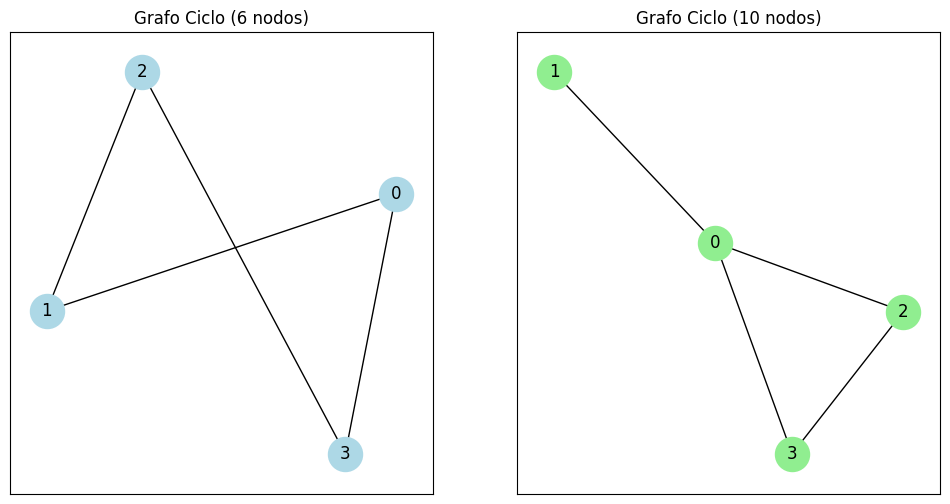

In [45]:
G_c1 = nx.cycle_graph(4)
G_c2 = nx.barabasi_albert_graph(4, 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
nx.draw_networkx(G_c1, ax=axes[0], node_color='lightblue', node_size=600, with_labels=True)
axes[0].set_title("Grafo Ciclo (6 nodos)")
nx.draw_networkx(G_c2, ax=axes[1], node_color='lightgreen', node_size=600, with_labels=True)
axes[1].set_title("Grafo Ciclo (10 nodos)")
plt.show()

In [46]:
# Convertimos la matriz de adyacencia de NetworkX al formato que espera grakel
A_c1 = nx.adjacency_matrix(G_c1).toarray()
A_c2 = nx.adjacency_matrix(G_c2).toarray()

grakel_c1 = Graph(A_c1)
grakel_c2 = Graph(A_c2)
Gs_cycles = list([grakel_c1, grakel_c2])

In [47]:
# El grado máximo de un producto de grafos ciclo C_m x C_n es 2 * 2 = 4.
# Por lo tanto, el máximo lambda permitido antes de que diverja es ~ 1/4 = 0.25.
lambdas = [0.01, 0.1]
similarities = []

for lam in lambdas:
    # method_type='fast' explota la decomposición propia, y normalize=True da valores de similitud entre 0 y 1
    gk = RandomWalk(normalize=True, lamda=float(lam), method_type="baseline")
    K = gk.fit_transform(Gs_cycles)
    print(K)

[[1.         0.99998682]
 [0.99998682 1.        ]]
[[1.         0.99707026]
 [0.99707026 1.        ]]


ValueError: x and y must have same first dimension, but have shapes (2,) and (0,)

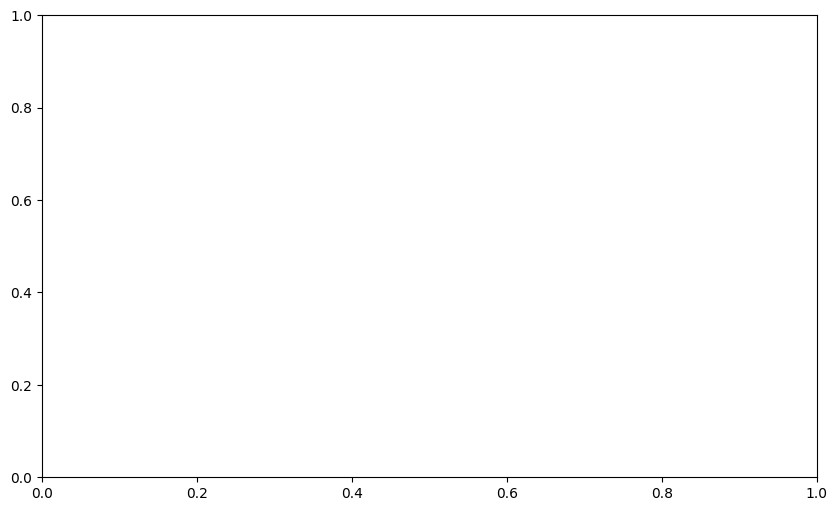

In [48]:
plt.figure(figsize=(10, 6))
plt.plot(lambdas, similarities, marker='o', linestyle='-', color='purple', linewidth=2)
plt.xlabel("Parámetro $\\lambda$", fontsize=12)
plt.ylabel("Similitud de Kernel Normalizado $K(G_1, G_2)$", fontsize=12)
plt.title("Similitud Random Walk Kernel vs $\\lambda$ (Grafos Ciclo)", fontsize=14)
plt.grid(True)
plt.show()